In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

plt.rcParams["font.family"] = "Hiragino Sans"  # 日本語表示用（macOS）

PROJECT_DIR = Path.home() / "applied_programming_ii" / "04"
DATA_DIR = Path.home() / "applied_programming_ii" / "data"
FIGURE_DIR = PROJECT_DIR / "reports" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("作業フォルダ:", PROJECT_DIR)
print("人口データの有無:", (DATA_DIR / "population_japan.csv").exists())

作業フォルダ: /Users/kkagawa/applied_programming_ii/04
人口データの有無: True


In [2]:
def exponential_rhs(t, N, r):
    """指数成長モデル dN/dt = r N の右辺．"""
    return r * N


def exponential_solution(t, N0, r, t0=0.0):
    """dN/dt = r N, N(t0) = N0 の解析解を返す．"""
    return N0 * np.exp(r * (t - t0))


def mean_squared_error(y_obs, y_model):
    """観測値とモデル値の平均二乗誤差を返す．"""
    return np.mean((y_obs - y_model) ** 2)


population = pd.read_csv(DATA_DIR / "population_japan.csv")
population["population_10k"] = population["total_population_thousand"] / 10

year_obs = population["year"].to_numpy()
t_obs = (year_obs - 1920).astype(float)          # 1920年を t = 0 とする [年]
y_obs = population["population_10k"].to_numpy()  # 観測値 [万人]
N0 = y_obs[0]                                     # 1920年の人口 [万人]

print(f"観測値の数: {len(y_obs)}，初期値 N0 = {N0:.1f} 万人")

観測値の数: 101，初期値 N0 = 5596.3 万人


In [ ]:
step = 5   # 差分をとる間隔 [年]

# 5年ごとの値を取り出す
mask_5y = (year_obs % 5 == 0)
year_5y = year_obs[mask_5y]
y_5y = y_obs[mask_5y]

print(y_5y)

# 一人あたりの増加率 (N_{k+1} - N_k) / (step * N_k) を計算する
per_capita_rate = (y_5y[1:] - y_5y[:-1]) / (step * y_5y[:-1])
N_start = y_5y[:-1]          # 各区間の始めの人口

[ 5596.3  5973.7  6445.   6925.4  7193.3  7214.7  8320.   8927.6  9341.9
  9827.5 10372.  11194.  11706.  12104.9 12361.1 12557.  12692.6 12776.8
 12805.7 12709.5 12614.6]


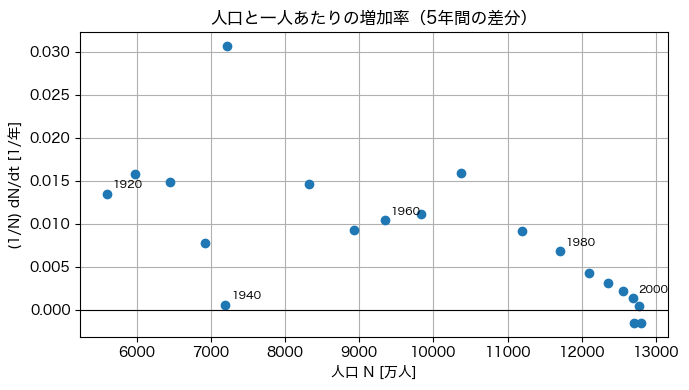

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(N_start, per_capita_rate, marker="o", linestyle="none")
for N_k, rate, yr in zip(N_start, per_capita_rate, year_5y[:-1]):
    if yr % 20 == 0:
        ax.annotate(str(yr), (N_k, rate), textcoords="offset points", xytext=(4, 4), fontsize=8)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("人口と一人あたりの増加率（5年間の差分）")
ax.set_xlabel("人口 N [万人]")
ax.set_ylabel("(1/N) dN/dt [1/年]")
ax.grid(True)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "per_capita_rate_vs_N.png", dpi=150)
plt.show()